In [3]:
import cvxeda
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
wesad_data = pd.read_csv("../Data/wesad_eda/filtered_eda_signals.csv")
wesad_data.iloc[:,0]

0        0.000000
1        0.024334
2        0.070629
3        0.112352
4        0.122235
           ...   
20887    0.372521
20888    0.378905
20889    0.391190
20890    0.402931
20891    0.406003
Name: S15_EDA, Length: 20892, dtype: float64

In [5]:
r, p, t, l, d, e, obj = cvxeda.cvxEDA(wesad_data.iloc[:,0], 1.0 / 4)

     pcost       dcost       gap    pres   dres
 0: -2.0588e+03 -2.0414e+03  2e+04  1e+02  5e-02
 1: -2.0424e+03 -3.1281e+03  1e+03  8e+00  3e-03
 2: -2.0424e+03 -2.1798e+03  1e+02  8e-01  3e-04
 3: -2.0439e+03 -2.0680e+03  2e+01  7e-02  2e-05
 4: -2.0556e+03 -2.0594e+03  4e+00  7e-03  2e-06
 5: -2.0576e+03 -2.0591e+03  1e+00  2e-03  7e-07
 6: -2.0584e+03 -2.0591e+03  7e-01  8e-04  3e-07
 7: -2.0587e+03 -2.0591e+03  4e-01  3e-04  1e-07
 8: -2.0589e+03 -2.0590e+03  1e-01  5e-05  2e-08
 9: -2.0590e+03 -2.0590e+03  4e-02  1e-05  4e-09
10: -2.0590e+03 -2.0590e+03  1e-02  3e-06  1e-09
11: -2.0590e+03 -2.0590e+03  3e-03  6e-07  2e-10
12: -2.0590e+03 -2.0590e+03  9e-04  6e-08  2e-11
13: -2.0590e+03 -2.0590e+03  3e-04  1e-08  4e-12
14: -2.0590e+03 -2.0590e+03  8e-05  2e-09  6e-13
15: -2.0590e+03 -2.0590e+03  2e-05  2e-10  7e-14
16: -2.0590e+03 -2.0590e+03  5e-06  4e-11  2e-14
17: -2.0590e+03 -2.0590e+03  1e-06  7e-12  6e-15
Optimal solution found.


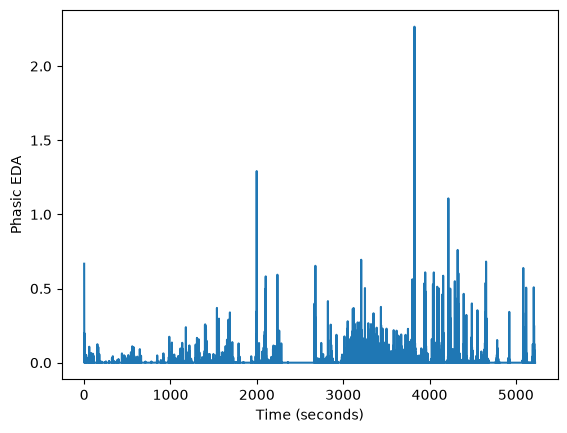

In [6]:
time = np.arange(len(p)) / 4

plt.plot(time, p, label='phasic component')
plt.xlabel('Time (seconds)')
plt.ylabel('Phasic EDA')
plt.show()

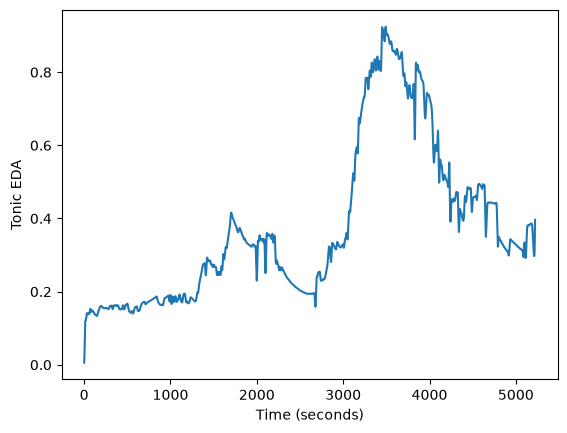

In [7]:
time = np.arange(len(t)) / 4

plt.plot(time, t)
plt.xlabel('Time (seconds)')
plt.ylabel('Tonic EDA')
plt.show()

In [8]:
tonic_signals = []
phasic_signals = []

# Dictionary of participant IDs
subject_ids = list(dict.fromkeys([col.split('_')[0] for col in wesad_data.columns]))

for subject_id in subject_ids:
    eda_col = f'{subject_id}_EDA'
    label_col = f'{subject_id}_Label'

    eda_signal = wesad_data.iloc[:,0]
    labels = wesad_data.iloc[:,1]

    # Apply cvxEDA decomposition
    r, p, t, l, d, e, obj = cvxeda.cvxEDA(eda_signal, 1.0 / 4)
        
    # Build the structured DataFrame for the current participant
    tonic_dataframe = pd.DataFrame({
            f'{subject_id}_Tonic': t,
            f'{subject_id}_Label': labels
        })

    phasic_dataframe = pd.DataFrame({
                    f'{subject_id}_Phasic': p,
                    f'{subject_id}_Label': labels
                })
        
    tonic_signals.append(tonic_dataframe)
    phasic_signals.append(phasic_dataframe)
    

        


# Combine all subject results
#final_filtered_data = pd.concat(filtered_signals, axis=1)

     pcost       dcost       gap    pres   dres
 0: -2.0588e+03 -2.0414e+03  2e+04  1e+02  5e-02
 1: -2.0424e+03 -3.1281e+03  1e+03  8e+00  3e-03
 2: -2.0424e+03 -2.1798e+03  1e+02  8e-01  3e-04
 3: -2.0439e+03 -2.0680e+03  2e+01  7e-02  2e-05
 4: -2.0556e+03 -2.0594e+03  4e+00  7e-03  2e-06
 5: -2.0576e+03 -2.0591e+03  1e+00  2e-03  7e-07
 6: -2.0584e+03 -2.0591e+03  7e-01  8e-04  3e-07
 7: -2.0587e+03 -2.0591e+03  4e-01  3e-04  1e-07
 8: -2.0589e+03 -2.0590e+03  1e-01  5e-05  2e-08
 9: -2.0590e+03 -2.0590e+03  4e-02  1e-05  4e-09
10: -2.0590e+03 -2.0590e+03  1e-02  3e-06  1e-09
11: -2.0590e+03 -2.0590e+03  3e-03  6e-07  2e-10
12: -2.0590e+03 -2.0590e+03  9e-04  6e-08  2e-11
13: -2.0590e+03 -2.0590e+03  3e-04  1e-08  4e-12
14: -2.0590e+03 -2.0590e+03  8e-05  2e-09  6e-13
15: -2.0590e+03 -2.0590e+03  2e-05  2e-10  7e-14
16: -2.0590e+03 -2.0590e+03  5e-06  4e-11  2e-14
17: -2.0590e+03 -2.0590e+03  1e-06  7e-12  6e-15
Optimal solution found.
     pcost       dcost       gap    pres   dre

In [9]:
tonic_csv = pd.concat(tonic_signals, axis=1)
tonic_csv

,S15_Tonic,S15_Label,S7_Tonic,S7_Label,S3_Tonic,S3_Label,S2_Tonic,S2_Label,S14_Tonic,S14_Label,...,S4_Tonic,S4_Label,S13_Tonic,S13_Label,S5_Tonic,S5_Label,S9_Tonic,S9_Label,S6_Tonic,S6_Label
0,0.005656,0.0,0.005656,0.0,0.005656,0.0,0.005656,0.0,0.005656,0.0,...,0.005656,0.0,0.005656,0.0,0.005656,0.0,0.005656,0.0,0.005656,0.0
1,0.005722,0.0,0.005722,0.0,0.005722,0.0,0.005722,0.0,0.005722,0.0,...,0.005722,0.0,0.005722,0.0,0.005722,0.0,0.005722,0.0,0.005722,0.0
2,0.006034,0.0,0.006034,0.0,0.006034,0.0,0.006034,0.0,0.006034,0.0,...,0.006034,0.0,0.006034,0.0,0.006034,0.0,0.006034,0.0,0.006034,0.0
3,0.006580,0.0,0.006580,0.0,0.006580,0.0,0.006580,0.0,0.006580,0.0,...,0.006580,0.0,0.006580,0.0,0.006580,0.0,0.006580,0.0,0.006580,0.0
4,0.007352,0.0,0.007352,0.0,0.007352,0.0,0.007352,0.0,0.007352,0.0,...,0.007352,0.0,0.007352,0.0,0.007352,0.0,0.007352,0.0,0.007352,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20887,0.375712,0.0,0.375712,0.0,0.375712,0.0,0.375712,0.0,0.375712,0.0,...,0.375712,0.0,0.375712,0.0,0.375712,0.0,0.375712,0.0,0.375712,0.0
20888,0.380679,0.0,0.380679,0.0,0.380679,0.0,0.380679,0.0,0.380679,0.0,...,0.380679,0.0,0.380679,0.0,0.380679,0.0,0.380679,0.0,0.380679,0.0
20889,0.385759,0.0,0.385759,0.0,0.385759,0.0,0.385759,0.0,0.385759,0.0,...,0.385759,0.0,0.385759,0.0,0.385759,0.0,0.385759,0.0,0.385759,0.0
20890,0.390943,0.0,0.390943,0.0,0.390943,0.0,0.390943,0.0,0.390943,0.0,...,0.390943,0.0,0.390943,0.0,0.390943,0.0,0.390943,0.0,0.390943,0.0


In [10]:
phasic_csv = pd.concat(phasic_signals, axis=1)
phasic_csv

,S15_Phasic,S15_Label,S7_Phasic,S7_Label,S3_Phasic,S3_Label,S2_Phasic,S2_Label,S14_Phasic,S14_Label,...,S4_Phasic,S4_Label,S13_Phasic,S13_Label,S5_Phasic,S5_Label,S9_Phasic,S9_Label,S6_Phasic,S6_Label
0,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0,...,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0,6.674665e-01,0.0
1,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0,...,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0,3.965376e-01,0.0
2,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0,...,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0,7.135253e-08,0.0
3,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0,...,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0,3.010073e-08,0.0
4,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0,...,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0,2.394813e-08,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20887,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0,...,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0,7.175971e-08,0.0
20888,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0,...,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0,1.616485e-07,0.0
20889,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0,...,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0,1.571731e-07,0.0
20890,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0,...,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0,9.511132e-08,0.0


In [11]:
tonic_csv.to_csv("../Data/wesad_eda/tonic_signal.csv", index=False)
phasic_csv.to_csv("../Data/wesad_eda/phasic_signal.csv", index=False)
